# Machine Learning Based Buyer Segmentation and Investment Profiling
**Real Estate Market Intelligence** · Unified Mentor × Parcl Co. Limited

This notebook walks through the whole project step by step using the real `clients.csv` and `properties.csv`.
The same logic is packaged in `src/` and run end-to-end by `python train_pipeline.py`.

**Workflow:** 1 Data understanding → 2 Cleaning → 3 EDA → 4 Features → 5 Encoding & scaling → 6 K-Means → 7 Hierarchical → 8 PCA → 9 Cluster profiles → 10 PRD check & tests → 11 Investment profile → 12 Insights.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('..'))          # so that `import src` works from the notebooks folder
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
from src.data_cleaning import load_raw_data, inspect_datasets, run_cleaning
from src.feature_engineering import select_features, make_feature_matrix, correlation_check
from src.clustering import sweep_kmeans, select_k, fit_final_kmeans, run_hierarchical, fit_pca
from src.profiling import (profile_clusters, name_clusters, trait_effects, test_prd_segments,
                           segment_tests, investment_profile)
from src.eda import make_eda_figures
from src import utils
sns.set_theme(style='whitegrid')

## Part 1 - Data understanding
We never assume the structure; we **discover** it: rows, columns, types, missing values, duplicates, unique values and a possible join key.

In [2]:
raw_clients, raw_props = load_raw_data()
audit = inspect_datasets(raw_clients, raw_props, verbose=True)
print()
print('CLIENTS columns   :', list(raw_clients.columns))
print('PROPERTIES columns:', list(raw_props.columns))

CLIENTS: 2000 rows x 12 columns
  columns: ['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth', 'gender', 'country', 'region', 'acquisition_purpose', 'satisfaction_score', 'loan_applied', 'referral_channel']
  missing values: 0 | duplicate rows: 0
PROPERTIES: 10000 rows x 9 columns
  columns: ['listing_id', 'tower_number', 'transaction_date', 'unit_category', 'unit_number', 'floor_area_sqft', 'sale_price', 'listing_status', 'client_ref']
  missing values: 2695 | duplicate rows: 0
JOIN: {'found': True, 'primary_key_in_clients': 'client_id', 'foreign_key_in_properties': 'client_ref', 'share_of_property_refs_matching': 1.0, 'clients_with_at_least_one_property': 2000, 'total_clients': 2000, 'properties_with_null_reference': 2695}

CLIENTS columns   : ['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth', 'gender', 'country', 'region', 'acquisition_purpose', 'satisfaction_score', 'loan_applied', 'referral_channel']
PROPERTIES columns: ['listing_id', 'to

In [3]:
print('--- clients: unique values per column ---'); print(pd.Series(audit['clients']['unique_values']).to_string())
print('\n--- properties: unique values per column ---'); print(pd.Series(audit['properties']['unique_values']).to_string())
print('\nMissing values (clients):', sum(audit['clients']['missing_values'].values()))
print('Missing values (properties):', {k:v for k,v in audit['properties']['missing_values'].items() if v})
print('\nText-format patterns (9 = a digit):'); print(pd.DataFrame(audit['format_patterns']).T.to_string())

--- clients: unique values per column ---
client_id              2000
client_type               2
first_name              337
last_name               224
date_of_birth          1889
gender                    2
country                  10
region                   57
acquisition_purpose       2
satisfaction_score        5
loan_applied              2
referral_channel          3

--- properties: unique values per column ---
listing_id          10000
tower_number           20
transaction_date       24
unit_category           2
unit_number            70
floor_area_sqft      1208
sale_price           9998
listing_status          2
client_ref           2000

Missing values (clients): 0
Missing values (properties): {'client_ref': 2695}

Text-format patterns (9 = a digit):
                             9/99/9999  99-99-9999  99/99/9999  $999,999.99  $99,999.99
clients.date_of_birth            871.0       855.0       274.0          NaN         NaN
properties.transaction_date        NaN     10000.0

**Findings.** `clients` is one row per client; `properties` is one row per listing. The foreign key `properties.client_ref` points to `clients.client_id`.
`client_ref` is empty only for *Available* listings (nobody bought them yet), which is correct. Dates are stored in mixed formats and prices as text like `$300,385.62`, so cleaning is required.

In [4]:
print(audit['join_analysis'])
print()
print('Fields in the PRD that the data does NOT contain:')
for k, v in audit['fields_missing_vs_prd'].items(): print(' -', k, '->', v)

{'found': True, 'primary_key_in_clients': 'client_id', 'foreign_key_in_properties': 'client_ref', 'share_of_property_refs_matching': 1.0, 'clients_with_at_least_one_property': 2000, 'total_clients': 2000, 'properties_with_null_reference': 2695}

Fields in the PRD that the data does NOT contain:
 - income / net worth -> not present (PRD mentions 'high income')
 - bedrooms / property type beyond Apartment-Office -> not present
 - loan amount -> not present (only a Yes/No flag)
 - first-time-buyer flag -> not present (every client owns 3+ units)
 - client_type value 'Corporate' -> dataset uses 'Company'


## Part 2 - Data cleaning
Every decision is logged. Outliers are **reported, not deleted** (expensive units are legitimate).

In [5]:
c = run_cleaning()
master, props, transactions = c['master'], c['properties'], c['transactions']
log = pd.DataFrame(c['log'])
print(log[['table','step','detail']].to_string(max_colwidth=95))

         table                                       step                                                                                          detail
0      clients                                 duplicates                         Removed exact duplicate rows and repeated client_id values (kept first)
1      clients                      normalise client_type       Case/whitespace fixed, synonyms of Corporate mapped to 'Company' (label used in the data)
2      clients                           normalise gender                                                  M/F -> Male/Female; anything else -> 'Unknown'
3      clients              normalise acquisition_purpose                                        Case fixed; 'Personal use' style labels mapped to 'Home'
4      clients                     normalise loan_applied                                                        yes/y/true/1 -> Yes ; no/n/false/0 -> No
5      clients  normalise country/region/referral_channel                   

In [6]:
print('Outlier report (IQR rule):')
print(pd.DataFrame(c['outliers']).T[['lower_bound','upper_bound','n_outliers','pct_outliers']].round(2))
print('\nMaster dataset (one row per client):', master.shape)
print(master.drop(columns=['date_of_birth','first_purchase','last_purchase']).head().to_string())

Outlier report (IQR rule):
                 lower_bound  upper_bound  n_outliers  pct_outliers
sale_price_usd     -92844.76    773870.97         0.0          0.00
floor_area_sqft      -293.00      2574.20         0.0          0.00
price_per_sqft        222.19       381.37        94.0          0.94

Master dataset (one row per client): (2000, 26)
  client_id client_type  gender country      region acquisition_purpose  satisfaction_score loan_applied referral_channel        age age_group  is_investment  loan_flag  is_company  is_international  n_units  total_spend      avg_price  max_price     avg_area  avg_price_per_sqft  office_share  n_towers
0     C0001  Individual  Female     USA  California                Home                   4          Yes          Website  57.557837     55-64              0          1           0                 0        4   1246764.72  311691.180000  496266.41   983.885000          319.963172           0.0         4
1     C0002  Individual    Male     USA  Cal

## Part 3 - Exploratory data analysis
Static versions of the charts are saved to `reports/figures/`; the dashboard shows interactive Plotly versions.

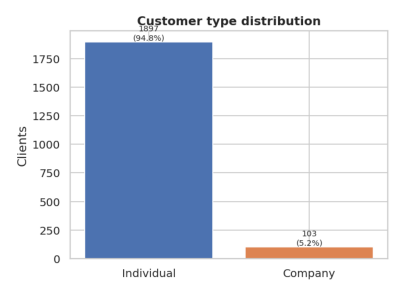

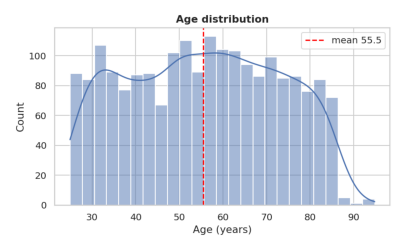

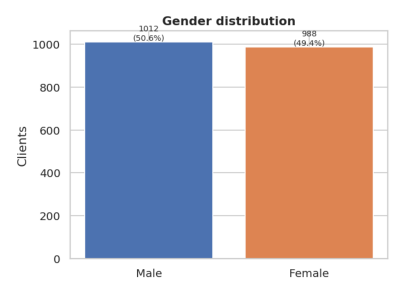

In [7]:
figs = make_eda_figures(master, props, transactions)
def show(name, w=7):
    img = plt.imread(str(utils.FIGURES_DIR / name))
    plt.figure(figsize=(w, w * img.shape[0] / img.shape[1])); plt.imshow(img); plt.axis('off'); plt.show()
for n in ['01_client_type.png','02_age.png','03_gender.png']: show(n, 5)

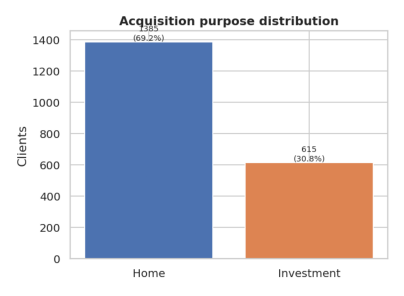

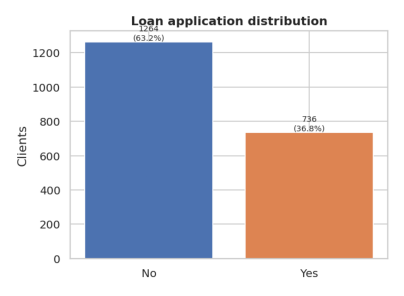

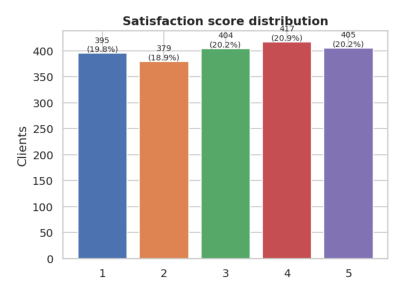

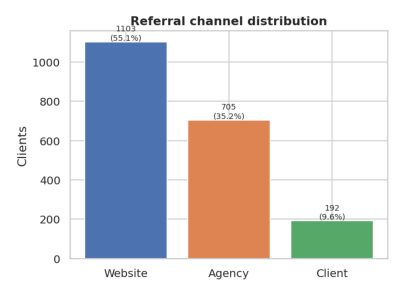

In [8]:
for n in ['04_acquisition_purpose.png','05_loan_applied.png','06_satisfaction.png','09_referral_channel.png']: show(n, 5)

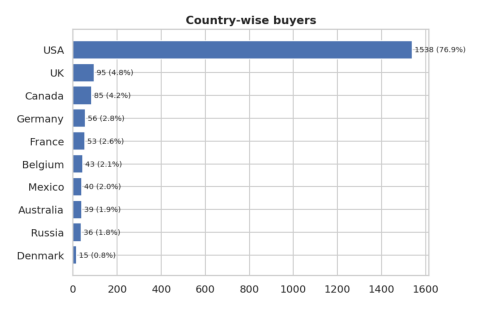

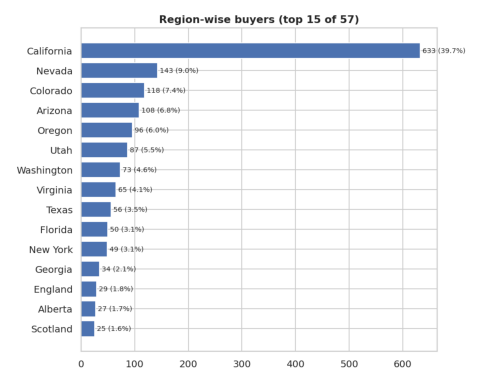

In [9]:
for n in ['08_country.png','07_region.png']: show(n, 6)

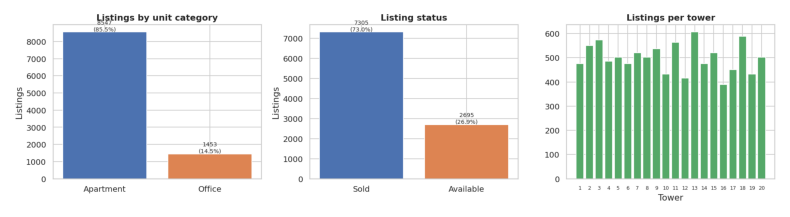

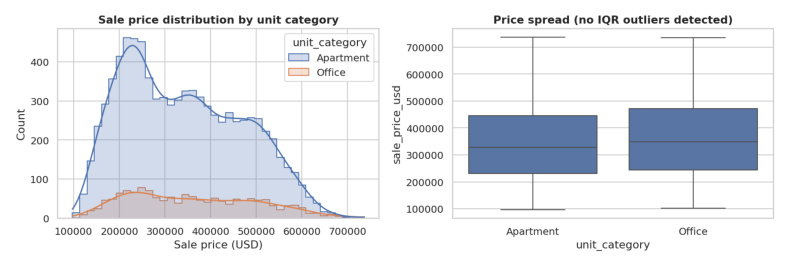

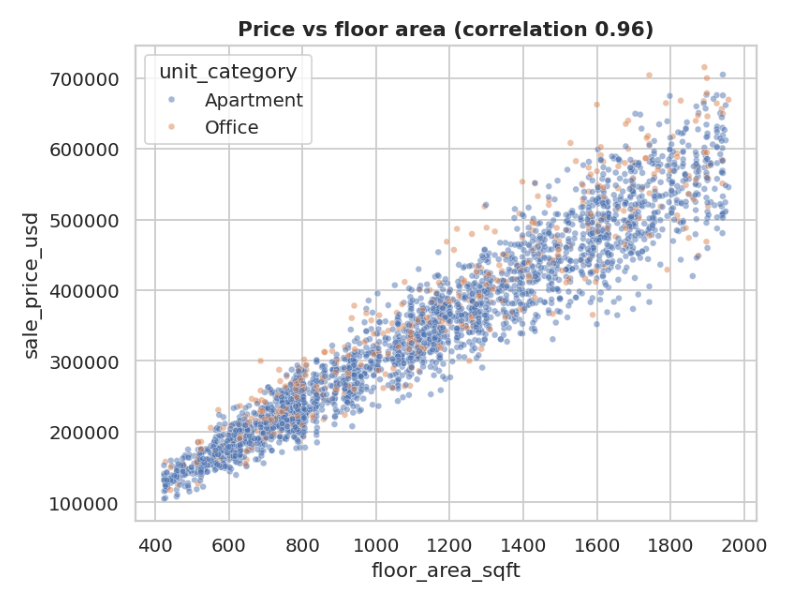

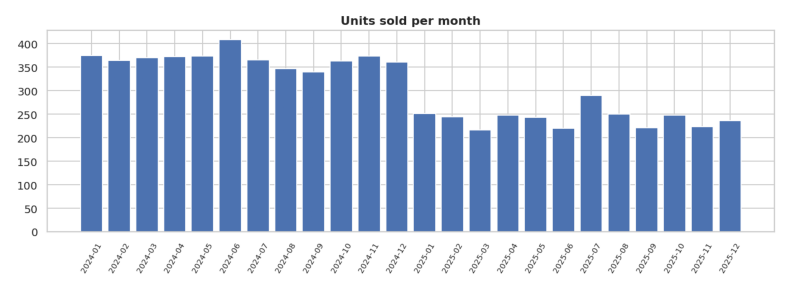

In [10]:
for n in ['10_property_stats.png','11_price_distribution.png','12_price_vs_area.png','13_monthly_sales.png']: show(n, 10)

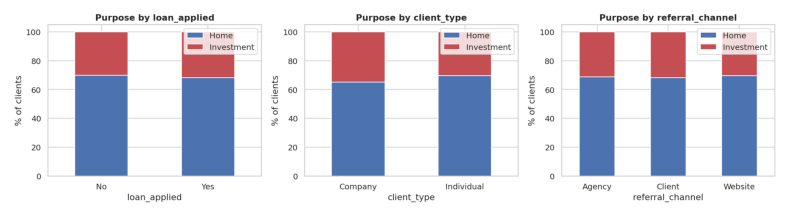

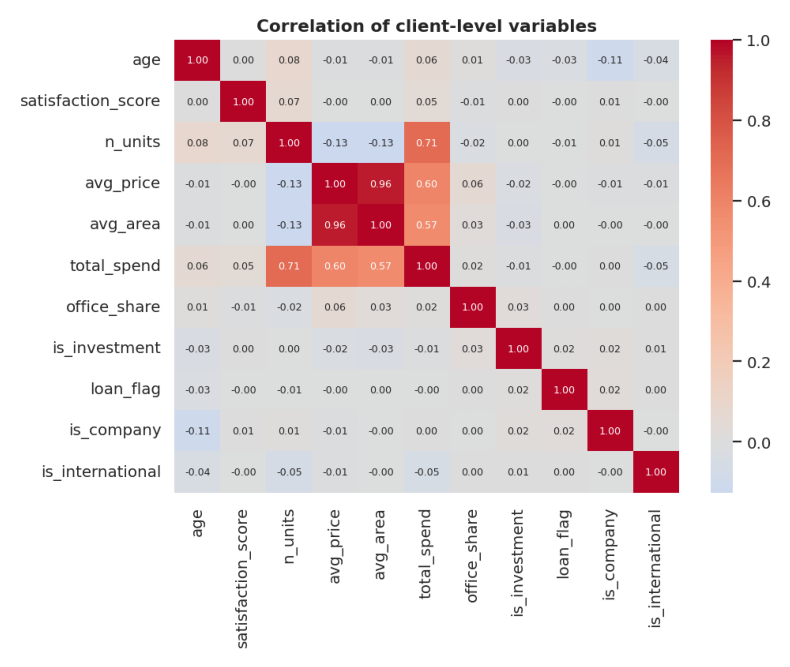

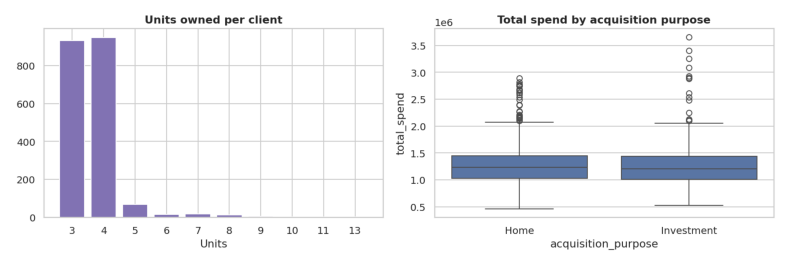

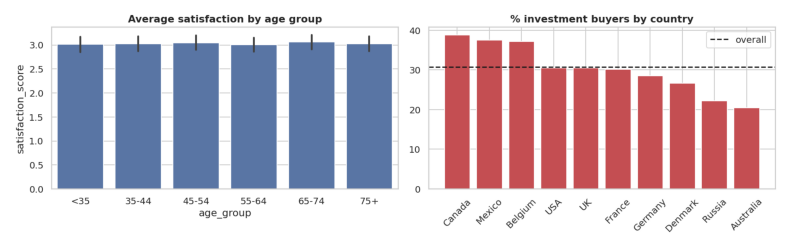

In [11]:
for n in ['14_purpose_relationships.png','15_correlation.png','16_units_and_spend.png','17_age_sat_country_invest.png']: show(n, 10)

**EDA take-aways.** Individuals are ~95% of clients; ~77% are in the USA; about 31% buy for investment; about 37% apply for a loan.
Price is almost exactly proportional to floor area. Purpose and loan are almost independent of every other variable - so we should *not* expect sharply separated clusters.

## Part 4 - Feature engineering
Per-client features come from aggregating each client's **sold** units. Only columns that exist are used; each has a reason.

In [12]:
cfg = select_features(master)
print('Numeric :', cfg['numeric']); print('Binary  :', cfg['binary']); print('Nominal :', cfg['nominal'])
print('\nWhy each feature is included:')
for k, v in cfg['reasons'].items(): print(f' - {k}: {v}')
print('\nWhy others are excluded:')
for k, v in cfg['excluded'].items(): print(f' - {k}: {v}')

Numeric : ['age', 'satisfaction_score', 'n_units', 'avg_price', 'office_share']
Binary  : ['acquisition_purpose', 'loan_applied', 'client_type']
Nominal : ['country', 'referral_channel']

Why each feature is included:
 - age: Life-stage of the buyer. Derived from date_of_birth (age is meaningful, a raw date is not).
 - satisfaction_score: Customer experience (1-5). Separates happy from unhappy buyers.
 - n_units: Portfolio size: how many units the client bought. Distinguishes bulk buyers from one-off buyers.
 - avg_price: Average price paid per unit (USD) = ticket size / budget level.
 - office_share: Share of the client's units that are Offices (0-1). Commercial vs residential appetite.
 - acquisition_purpose: Investment vs Home. The core investment-motivation signal requested in the PRD.
 - loan_applied: Financing dependence (Yes/No).
 - client_type: Individual vs Company.
 - country: Geographic market. Region is nested inside country, so country is used (see EXCLUDED).
 - referral_c

In [13]:
print(correlation_check(master, ['age','satisfaction_score','n_units','avg_price','avg_area','total_spend','office_share','avg_price_per_sqft']))

                      age  satisfaction_score  n_units  avg_price  avg_area  total_spend  office_share  avg_price_per_sqft
age                 1.000               0.004    0.083     -0.015    -0.011        0.057         0.014              -0.007
satisfaction_score  0.004               1.000    0.070     -0.003     0.000        0.049        -0.011              -0.017
n_units             0.083               0.070    1.000     -0.126    -0.125        0.710        -0.021              -0.027
avg_price          -0.015              -0.003   -0.126      1.000     0.959        0.596         0.056               0.270
avg_area           -0.011               0.000   -0.125      0.959     1.000        0.569         0.029               0.003
total_spend         0.057               0.049    0.710      0.596     0.569        1.000         0.017               0.165
office_share        0.014              -0.011   -0.021      0.056     0.029        0.017         1.000               0.107
avg_price_per_sq

## Parts 5 & 6 - Encoding and scaling (one sklearn `ColumnTransformer`)
* numeric → `StandardScaler` (distance-based clustering needs comparable scales)
* binary (purpose, loan, client type) → label-encoded 0/1
* nominal (country, referral channel) → one-hot (no fake order)

In [14]:
X, preprocessor, feature_names = make_feature_matrix(master, cfg)
print('Feature matrix:', X.shape); print(feature_names)
print('\nMean / std of the scaled numeric columns:')
print(pd.DataFrame(X[:, :len(cfg['numeric'])], columns=cfg['numeric']).agg(['mean','std']).round(3))

Feature matrix: (2000, 21)
['age', 'satisfaction_score', 'n_units', 'avg_price', 'office_share', 'acquisition_purpose', 'loan_applied', 'client_type', 'country_Australia', 'country_Belgium', 'country_Canada', 'country_Denmark', 'country_France', 'country_Germany', 'country_Mexico', 'country_Russia', 'country_UK', 'country_USA', 'referral_channel_Agency', 'referral_channel_Client', 'referral_channel_Website']

Mean / std of the scaled numeric columns:
      age  satisfaction_score  n_units  avg_price  office_share
mean  0.0                 0.0      0.0       -0.0           0.0
std   1.0                 1.0      1.0        1.0           1.0


## Part 7 - K-Means: choosing K
We test K = 2…10 and look at inertia (elbow), silhouette, Davies-Bouldin and **stability** (does the same clustering appear after random restarts?).

In [15]:
sweep = sweep_kmeans(X)
print(sweep.round(3).to_string(index=False))

 k   inertia  silhouette  davies_bouldin  calinski_harabasz  stability_ari  smallest_cluster_pct
 2 11295.751       0.133           2.527            286.665          0.212                 44.85
 3 10290.394       0.117           2.263            254.809          0.769                 27.70
 4  9389.279       0.124           1.874            249.937          0.431                  2.50
 5  8679.020       0.124           1.786            243.507          0.391                  2.55
 6  8086.893       0.123           1.696            238.165          0.684                  2.55
 7  7694.181       0.121           1.770            225.450          0.679                  2.55
 8  7363.983       0.118           1.750            214.567          0.746                  2.55
 9  7082.284       0.120           1.789            205.014          0.711                  2.50
10  6861.404       0.121           1.793            195.125          0.643                  2.35


Elbow method suggests K=6; the unrestricted silhouette peak is K=2 (a trivial 2-way split). Restricting to 3-6 segments (business limit), K values with silhouette within 0.01 of the best (0.124): [3, 4, 5, 6]. Of these, K values with stability ARI >= 0.6: [3, 6]. K=6 has the lowest Davies-Bouldin index (1.696) among them (silhouette=0.123, stability ARI=0.68).


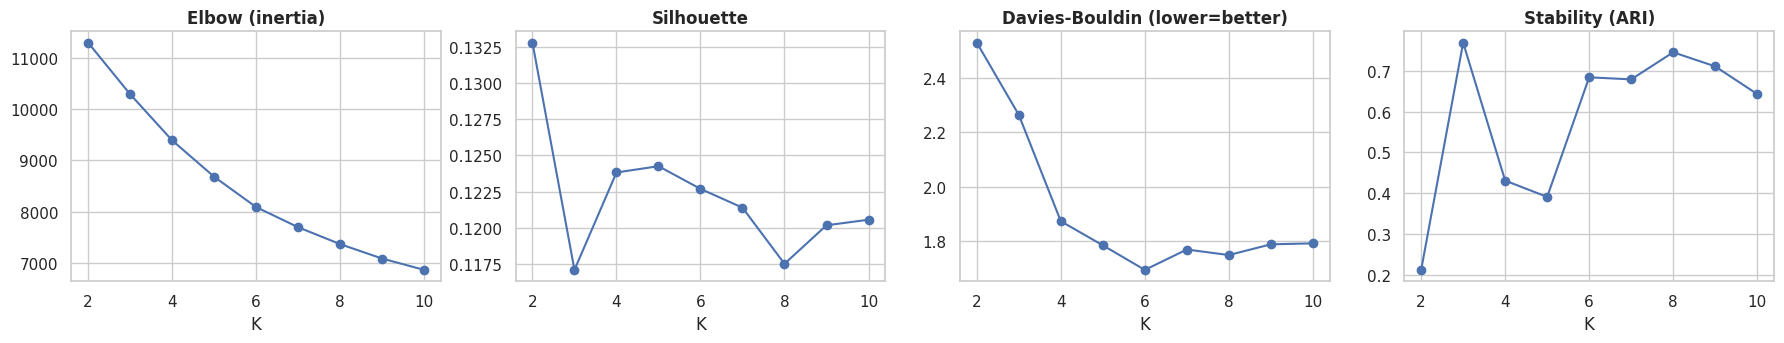

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, col, t in zip(ax, ['inertia','silhouette','davies_bouldin','stability_ari'],
                     ['Elbow (inertia)','Silhouette','Davies-Bouldin (lower=better)','Stability (ARI)']):
    a.plot(sweep['k'], sweep[col], 'o-'); a.set_title(t, fontweight='bold'); a.set_xlabel('K')
plt.tight_layout(); plt.show()
sel = select_k(sweep); print(sel['rationale'])

**Reading the plots.** The silhouette curve is almost flat from K=3 to 6 (≈0.12), so it cannot choose K alone. The elbow, Davies-Bouldin and stability point to K=6 and clusters are interpretable.
A silhouette near 0.12 means the groups **overlap**; this is a property of the data, and we report it honestly.

In [17]:
k = sel['k']
kmeans, labels = fit_final_kmeans(X, k)
master['cluster'] = labels
print('K =', k); print(pd.Series(labels).value_counts().sort_index().rename('clients').to_frame().T)

K = 6
           0    1    2    3    4   5
clients  437  415  397  387  313  51


## Part 8 - Hierarchical clustering (Ward) and comparison

In [18]:
hier = run_hierarchical(X, k, labels)
print(hier['linkage_comparison'].round(3).to_string(index=False))
print({kk: round(v, 3) for kk, v in hier['agreement'].items()})
print('\nK-Means (rows) vs Ward (columns):'); print(hier['contingency'])

 linkage  silhouette  davies_bouldin  smallest_cluster_pct  ARI_vs_kmeans
    ward       0.090           2.207                  2.00          0.245
 average       0.182           1.053                  0.05          0.017
complete       0.062           2.002                  0.15          0.140
{'ARI': 0.245, 'NMI': 0.361, 'cophenetic_correlation_ward': 0.342, 'silhouette_ward': 0.09, 'silhouette_kmeans': 0.123, 'davies_bouldin_ward': 2.207, 'davies_bouldin_kmeans': 1.695}

K-Means (rows) vs Ward (columns):
ward      0    1    2    3    4   5
kmeans                             
0         0    5   37  204  191   0
1       156  229    0   29    1   0
2       264   12   18  102    1   0
3        34  214    0   22  117   0
4       112   31  104   15   51   0
5         0    0    0   11    0  40


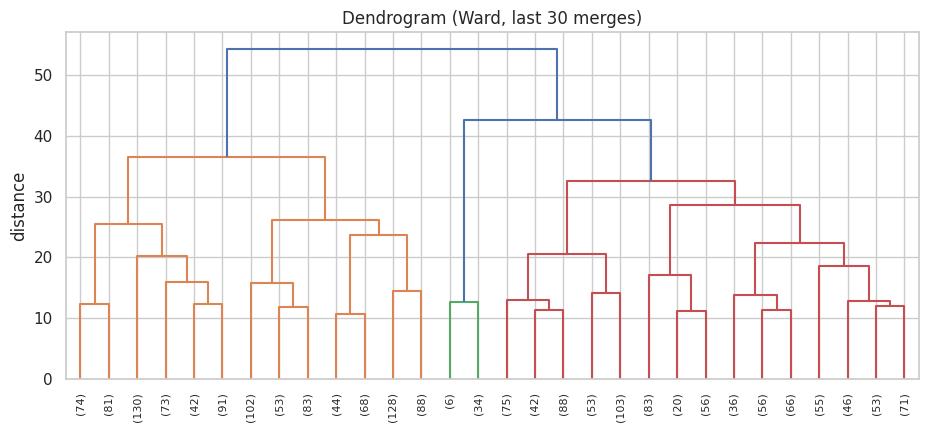

In [19]:
from scipy.cluster.hierarchy import dendrogram
fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(hier['linkage_matrix'], truncate_mode='lastp', p=30, ax=ax, leaf_rotation=90, leaf_font_size=8)
ax.set_title('Dendrogram (Ward, last 30 merges)'); ax.set_ylabel('distance'); plt.show()

**Comparison.** Ward gives a lower silhouette and only partial agreement (ARI ≈ 0.25) with K-Means; both isolate the small high-volume group.
*Average* linkage has a high silhouette only because it creates tiny clusters. K-Means is kept as the production model: better metrics, repeatable, and it can score new clients.

## Part 9 - PCA (visualisation only)

Explained variance: [0.184 0.16 ] total 0.343


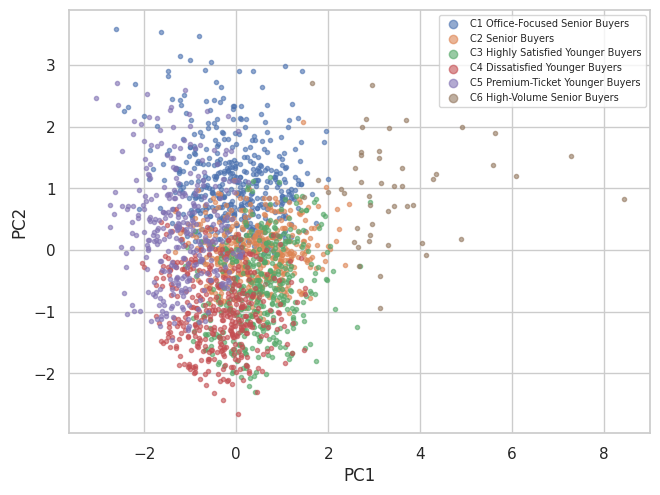

In [20]:
pca, coords = fit_pca(X)
master['pca1'], master['pca2'] = coords[:, 0], coords[:, 1]
print('Explained variance:', pca.explained_variance_ratio_.round(3), 'total', pca.explained_variance_ratio_.sum().round(3))
names = name_clusters(master)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for cid, g in master.groupby('cluster'):
    ax.scatter(g.pca1, g.pca2, s=9, alpha=.6, label=f'C{cid+1} {names[cid]}')
ax.legend(fontsize=7, markerscale=2); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); plt.show()

## Part 10 - Cluster interpretation
Names come from the data: each cluster's two strongest distinguishing traits (effect size = distance from the overall mean in standard deviations).

In [21]:
master['cluster_id'] = master['cluster'].map(lambda i: f'C{i+1}'); master['segment'] = master['cluster'].map(names)
prof = profile_clusters(master); eff = trait_effects(master)
show_cols = ['size','pct_of_clients','avg_age','pct_company','investment_rate','loan_rate','avg_satisfaction',
             'avg_units','avg_price','office_share','pct_international','top_country','top_region','value_index']
out = prof[show_cols].copy(); out.insert(0, 'segment', [names.get(i, 'All clients') for i in out.index])
print(out.round(3).to_string())

                             segment  size pct_of_clients    avg_age pct_company investment_rate loan_rate avg_satisfaction avg_units      avg_price office_share pct_international top_country  top_region value_index
0       Office-Focused Senior Buyers   437         0.2185  65.885402    0.025172        0.311213  0.347826         2.860412  3.581236  331202.199235     0.375667           0.23341         USA  California    0.940227
1                      Senior Buyers   415         0.2075  72.370804    0.021687        0.284337  0.337349         2.749398  3.563855  343253.484055     0.000482          0.216867         USA  California     0.97111
2    Highly Satisfied Younger Buyers   397         0.1985  46.334407     0.06801        0.277078  0.415617         4.531486  3.687657  311772.761709     0.074181          0.251889         USA  California    0.913543
3        Dissatisfied Younger Buyers   387         0.1935  40.014404    0.085271        0.325581  0.366925         1.666667  3.596899   

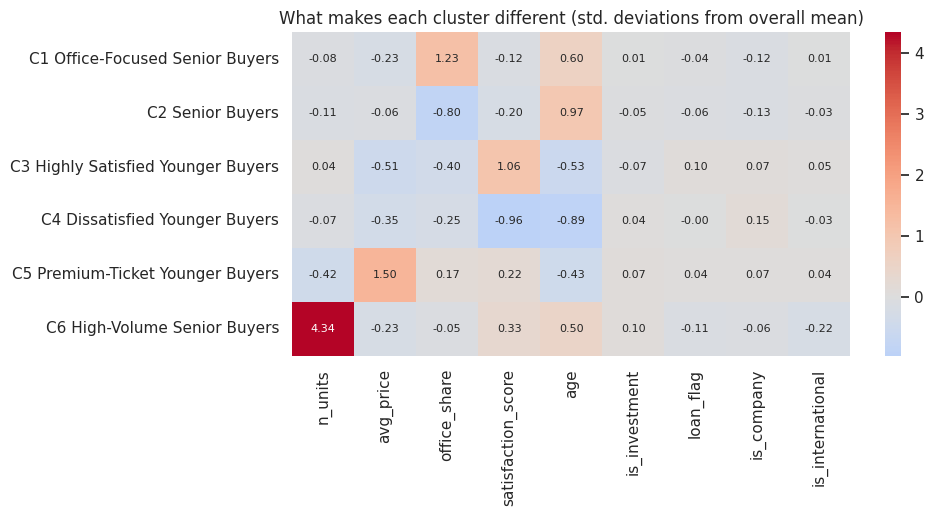

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.2))
e = eff.copy(); e.index = [f'C{i+1} {names[i]}' for i in e.index]
sns.heatmap(e, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, annot_kws={'size': 8})
ax.set_title('What makes each cluster different (std. deviations from overall mean)'); plt.show()

## Do the PRD's example segments exist? And which variables really differ?

In [23]:
prd = test_prd_segments(prof, names)
print(prd[['prd_segment','closest_cluster_name','conditions_met','supported_by_data']].to_string(index=False))
print('\nEvidence for the closest cluster of each concept:')
for _, r in prd.iterrows(): print('-', r['prd_segment'], '|', r['evidence'])

      prd_segment            closest_cluster_name conditions_met  supported_by_data
 Global Investors   Premium-Ticket Younger Buyers            0/2              False
First-Time Buyers Highly Satisfied Younger Buyers            1/3              False
 Corporate Buyers       High-Volume Senior Buyers            1/2              False
 Luxury Investors   Premium-Ticket Younger Buyers            2/3              False

Evidence for the closest cluster of each concept:
- Global Investors | investment_rate: 0.342 vs 0.307 overall (x1.11, need >= 1.25) -> no | pct_international: 0.249 vs 0.231 overall (x1.08, need >= 1.25) -> no
- First-Time Buyers | avg_age: 46.3 vs 55.5 overall (x0.83, need <= 0.85) -> OK | loan_rate: 0.416 vs 0.368 overall (x1.13, need >= 1.25) -> no | investment_rate: 0.277 vs 0.307 overall (x0.90, need <= 0.9) -> no
- Corporate Buyers | pct_company: 0.0392 vs 0.0515 overall (x0.76, need >= 1.25) -> no | avg_units: 7.29 vs 3.65 overall (x2.00, need >= 1.25) -> OK
- Luxu

In [24]:
tests = segment_tests(master)
print(tests[['variable','test','p_value','effect_size','effect_size_name','significant_0.05','used_as_model_input']].round(4).to_string(index=False))

           variable           test  p_value  effect_size effect_size_name  significant_0.05  used_as_model_input
acquisition_purpose     chi-square   0.3447       0.0530       Cramer's V             False                 True
       loan_applied     chi-square   0.1910       0.0609       Cramer's V             False                 True
        client_type     chi-square   0.0001       0.1156       Cramer's V              True                 True
   referral_channel     chi-square   0.1183       0.0620       Cramer's V             False                 True
            country     chi-square   0.7752       0.0613       Cramer's V             False                 True
             gender     chi-square   0.5829       0.0434       Cramer's V             False                False
                age Kruskal-Wallis   0.0000       0.5193      eta-squared              True                 True
 satisfaction_score Kruskal-Wallis   0.0000       0.4257      eta-squared              True     

**Honest conclusion.** None of the four PRD segments is fully supported, and purpose / loan / channel / country / gender do **not** differ significantly between clusters.
The clusters are about *age, satisfaction, portfolio size, ticket price and office share*.

## Part 11 - Investment profile

In [25]:
inv = investment_profile(master, prof, names)
print(inv.round(3).drop(columns=['investor_top_country']).to_string(index=False))

 cluster                         segment  clients  investors  investment_rate  investment_lift_vs_overall  investor_spend_usd  share_of_all_investor_spend  avg_units_per_investor  avg_unit_price_investor  investor_loan_rate  investor_avg_satisfaction  investor_value_rank
       0    Office-Focused Senior Buyers      437        136            0.311                       1.012        157042539.19                        0.204                   3.544               326047.571               0.375                      2.912                    2
       1                   Senior Buyers      415        118            0.284                       0.925        137976932.68                        0.179                   3.475               336179.140               0.280                      2.797                    4
       2 Highly Satisfied Younger Buyers      397        110            0.277                       0.901        126926652.13                        0.165                   3.700      

## Part 12 - Business insights per cluster
Data-supported findings and assumptions are kept separate. (Full text for all clusters is in `research_report.md` and the dashboard's *Segment Insights* page.)

In [26]:
from src.profiling import build_cluster_insights
insights = build_cluster_insights(master, prof, names, eff, inv)
for i in insights[:3]:
    print('='*80); print(i['headline'])
    print('Customer   :', i['customer_profile']); print('Investment :', i['investment_profile'])
    print('Financing  :', i['financing_profile'])
    print('Marketing  :'); [print('   -', r) for r in i['marketing_recommendations']]
    print('Property   :'); [print('   -', r) for r in i['property_recommendations']]
    print('Assumption :', i['assumptions'][-1])

Office-Focused Senior Buyers - 437 clients (21.9%)
Customer   : Office-Focused Senior Buyers: average age 66, 50% female, 2.5% companies, 23% international.
Investment : 31.1% buy for investment (lift 1.01x vs overall); this cluster holds 20.4% of all investor spend (136 investors, rank 2 of 6). Average unit price $331,202.
Financing  : 34.8% applied for a loan (in line with the overall 36.8%).
Marketing  :
   - Advisor-led, relationship-based outreach (events, phone/in-person) for an older audience.
Property   :
   - Office / commercial units: 38% of their purchases are offices (overall 15%).
   - Geography does not set this segment apart (country mix is close to the overall mix), so use the standard regional inventory.
Assumption : Marketing recommendations are rule-based interpretations of the measured traits; their effect on conversion has not been tested (no campaign data available).
Senior Buyers - 415 clients (20.8%)
Customer   : Senior Buyers: average age 72, 50% female, 2.2% c

## Saving models
Models and tables are saved by running **`python train_pipeline.py`** (it reproduces this notebook and writes `kmeans_model.pkl`, `scaler.pkl`, `preprocessor.pkl`, `pca.pkl`). The dashboard loads those files.

In [27]:
import joblib
for f in [utils.KMEANS_PKL, utils.SCALER_PKL, utils.PREPROCESSOR_PKL, utils.PCA_PKL]:
    print(f.name, '->', 'exists' if f.exists() else 'run train_pipeline.py')
km = joblib.load(utils.KMEANS_PKL); print('Saved model agrees with this notebook:', (km.predict(X) == labels).mean() == 1.0)

kmeans_model.pkl -> exists
scaler.pkl -> exists
preprocessor.pkl -> exists
pca.pkl -> exists
Saved model agrees with this notebook: True
